In [5]:
import pandas as pd

df = pd.read_csv(r"C:\Users\BCA25\OneDrive\Desktop\archive (1)\insurance.csv")

print("--- First 5 Rows ---")
display(df.head())

print(f"\nDataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

print("\nColumn Names:")
print(list(df.columns))

--- First 5 Rows ---


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Dataset Shape: 1338 rows, 7 columns

Column Names:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


In [6]:
import pandas as pd
df = pd.read_csv(r"C:\Users\BCA25\OneDrive\Desktop\archive (1)\insurance.csv")
Y = df["charges"]
X = df[["age"]]
X_all = df.drop(columns=["charges"])

print("Target variable (Y): 'charges'")
print(f"Target shape: {Y.shape}")
print("\nInput feature (X) for Age-based Linear Regression:")
print(X.head())
print(f"X shape: {X.shape}")

print("\nAll available predictor columns in dataset:")
print(list(X_all.columns))

Target variable (Y): 'charges'
Target shape: (1338,)

Input feature (X) for Age-based Linear Regression:
   age
0   19
1   18
2   28
3   33
4   32
X shape: (1338, 1)

All available predictor columns in dataset:
['age', 'sex', 'bmi', 'children', 'smoker', 'region']


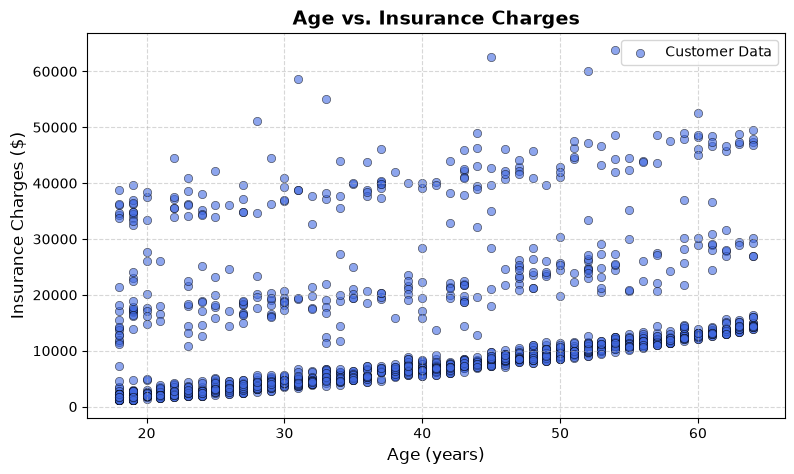

Observation:
1. There is an upward linear trend: as age increases, baseline insurance charges consistently increase.
2. The data exhibits three distinct tiers/bands, reflecting other influential factors (such as smoking status and BMI).


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(r"C:\Users\BCA25\OneDrive\Desktop\archive (1)\insurance.csv")
plt.figure(figsize=(9, 5))
plt.scatter(df["age"], df["charges"], color="royalblue", alpha=0.6, edgecolors="k", linewidth=0.5, label="Customer Data")
plt.title("Age vs. Insurance Charges", fontsize=14, fontweight="bold")
plt.xlabel("Age (years)", fontsize=12)
plt.ylabel("Insurance Charges ($)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

print("Observation:")
print("1. There is an upward linear trend: as age increases, baseline insurance charges consistently increase.")
print("2. The data exhibits three distinct tiers/bands, reflecting other influential factors (such as smoking status and BMI).")

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split


df = pd.read_csv(r"C:\Users\BCA25\OneDrive\Desktop\archive (1)\insurance.csv")


X = df.drop(columns=["charges"])
Y = df["charges"]


X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

print(f"Training set size (80%): {X_train.shape[0]} samples")
print(f"Testing set size (20%):  {X_test.shape[0]} samples")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")

Training set size (80%): 1070 samples
Testing set size (20%):  268 samples
X_train shape: (1070, 6)
X_test shape:  (268, 6)


In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


file_path = r"C:\Users\BCA25\OneDrive\Desktop\archive (1)\insurance.csv"
df = pd.read_csv(file_path)


X = df[['age']]      # Double brackets keep X as a 2D DataFrame
y = df['charges']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


model = LinearRegression()
model.fit(X_train, y_train)

slope = model.coef_[0]
intercept = model.intercept_

print("Model Training Completed Successfully!")
print(f"Slope (Coefficient): {slope:.4f}")
print(f"Intercept:           {intercept:.4f}")
print(f"\nRegression Equation: Charges = ({slope:.2f} * Age) + ({intercept:.2f})")
print(f"Interpretation: For each additional year of age, annual insurance charges increase by approximately ${slope:.2f}.")

Model Training Completed Successfully!
Slope (Coefficient): 240.5966
Intercept:           3876.9287

Regression Equation: Charges = (240.60 * Age) + (3876.93)
Interpretation: For each additional year of age, annual insurance charges increase by approximately $240.60.


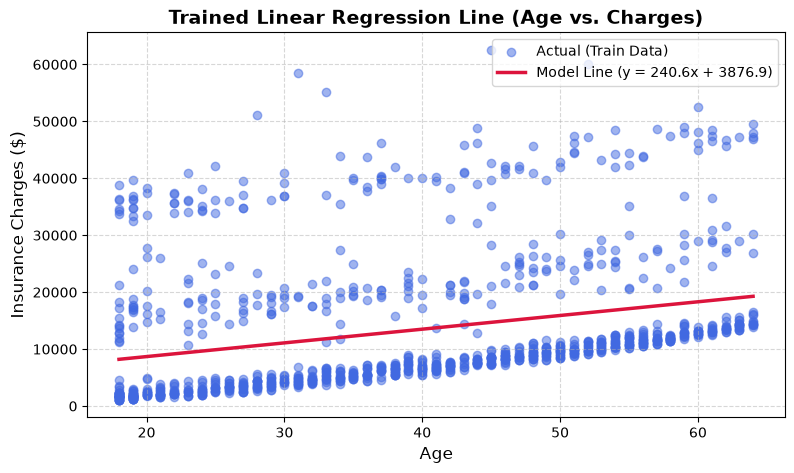

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


file_path = r"C:\Users\BCA25\OneDrive\Desktop\archive (1)\insurance.csv"
df = pd.read_csv(file_path)


X = df[["age"]]
y = df["charges"]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


model = LinearRegression()
model.fit(X_train, y_train)

slope = model.coef_[0]
intercept = model.intercept_


pred_train = model.predict(X_train)
order = np.argsort(X_train["age"].values)

plt.figure(figsize=(9, 5))
plt.scatter(X_train["age"], y_train, color="royalblue", alpha=0.5, label="Actual (Train Data)")
plt.plot(
    X_train["age"].values[order],
    pred_train[order],
    color="crimson", linewidth=2.5, label=f"Model Line (y = {slope:.1f}x + {intercept:.1f})"
)
plt.title("Trained Linear Regression Line (Age vs. Charges)", fontsize=14, fontweight="bold")
plt.xlabel("Age", fontsize=12)
plt.ylabel("Insurance Charges ($)", fontsize=12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [11]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# 1. THE PATH APPEARS HERE (at the start when loading the dataset)
df = pd.read_csv(r"C:\Users\BCA25\OneDrive\Desktop\archive (1)\insurance.csv")

# 2. Preprocess categorical columns ('sex', 'smoker', 'region') into numeric values
df_encoded = pd.get_dummies(df, drop_first=True)

# 3. Separate features (X) and target (y)
X = df_encoded.drop("charges", axis=1)
y = df_encoded["charges"]

# 4. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# --- YOUR ORIGINAL CODE STARTS HERE ---
y_pred = model.predict(X_test)

# Create comparison table
comparison_df = pd.DataFrame({
    "Age": X_test["age"].values,
    "Actual Charges ($)": y_test.values,
    "Predicted Charges ($)": y_pred,
    "Difference / Error ($)": y_test.values - y_pred,
})

print("--- Actual vs. Predicted Values (First 10 Test Samples) ---")
display(comparison_df.head(10).round(2))  # Use print() if not in Jupyter/Colab

--- Actual vs. Predicted Values (First 10 Test Samples) ---


,Age,Actual Charges ($),Predicted Charges ($),Difference / Error ($)
0,45,9095.07,8969.55,125.52
1,36,5272.18,7068.75,-1796.57
2,64,29330.98,36858.41,-7527.43
3,46,9301.89,9454.68,-152.78
4,19,33750.29,26973.17,6777.12
5,34,4536.26,10864.11,-6327.85
6,19,2117.34,170.28,1947.06
7,64,14210.54,16903.45,-2692.91
8,28,3732.63,1092.43,2640.19
9,49,10264.44,11218.34,-953.90


In [12]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Task 1: Load the Dataset (THE PATH GOES HERE)
df = pd.read_csv(r"C:\Users\BCA25\OneDrive\Desktop\archive (1)\insurance.csv")

# Task 2 & 3: Define Features (Age Only) and Target
X = df[["age"]]
y = df["charges"]

# Task 4: Split the Data into Training and Testing Sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Task 5: Train the Simple Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# Task 6: Make Predictions
y_pred = model.predict(X_test)

# Task 7: Model Evaluation Metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("=== Simple Linear Regression Evaluation (Age Only) ===")
print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

=== Simple Linear Regression Evaluation (Age Only) ===
Mean Absolute Error (MAE): $9,173.26
Root Mean Squared Error (RMSE): $11,661.22
R² Score: 0.1241
